   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 13.2 MB/s eta 0:00:00


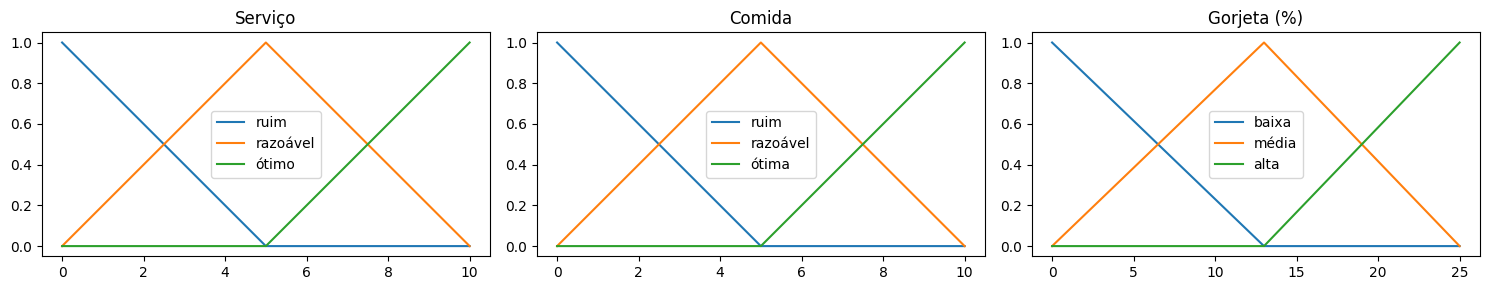

Gorjeta sugerida (%): 21.0


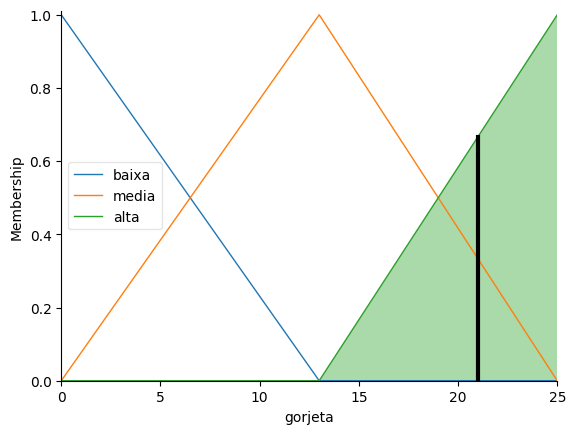

In [ ]:
# ============================================
# Lógica Fuzzy: Serviço, Comida e Gorjeta
# Atividade guiada em Python / Google Colab
# ============================================

# 1) IMPORTAÇÕES E SETUP
# ----------------------

!pip install scikit-fuzzy

import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt

# 2) DEFINIÇÃO DAS VARIÁVEIS LINGUÍSTICAS
# ----------------------------------------
# Universo de discurso:
# serviço/comida: notas de 0 a 10
# gorjeta: de 0 a 25 (%)

servico = ctrl.Antecedent(np.arange(0, 11, 1), 'servico')
comida  = ctrl.Antecedent(np.arange(0, 11, 1), 'comida')
gorjeta = ctrl.Consequent(np.arange(0, 26, 1), 'gorjeta')

# 3) FUNÇÕES DE PERTINÊNCIA
# --------------------------
# funções triangulares simples para cada termo linguístico.

# Serviço: ruim, razoavel, otimo
servico['ruim']      = fuzz.trimf(servico.universe, [0, 0, 5])
servico['razoavel']  = fuzz.trimf(servico.universe, [0, 5, 10])
servico['otimo']     = fuzz.trimf(servico.universe, [5, 10, 10])

# Comida: ruim, razoavel, otima
comida['ruim']       = fuzz.trimf(comida.universe, [0, 0, 5])
comida['razoavel']   = fuzz.trimf(comida.universe, [0, 5, 10])
comida['otima']      = fuzz.trimf(comida.universe, [5, 10, 10])

# Gorjeta: baixa, media, alta
gorjeta['baixa'] = fuzz.trimf(gorjeta.universe, [0, 0, 13])
gorjeta['media'] = fuzz.trimf(gorjeta.universe, [0, 13, 25])
gorjeta['alta']  = fuzz.trimf(gorjeta.universe, [13, 25, 25])

# 4) VISUALIZAÇÃO DAS FUNÇÕES DE PERTINÊNCIA
# -------------------------------------------

fig, axs = plt.subplots(1, 3, figsize=(15, 3))

# Serviço
axs[0].plot(servico.universe, servico['ruim'].mf,      label='ruim')
axs[0].plot(servico.universe, servico['razoavel'].mf,  label='razoável')
axs[0].plot(servico.universe, servico['otimo'].mf,     label='ótimo')
axs[0].set_title('Serviço')
axs[0].legend()

# Comida
axs[1].plot(comida.universe, comida['ruim'].mf,      label='ruim')
axs[1].plot(comida.universe, comida['razoavel'].mf,  label='razoável')
axs[1].plot(comida.universe, comida['otima'].mf,     label='ótima')
axs[1].set_title('Comida')
axs[1].legend()

# Gorjeta
axs[2].plot(gorjeta.universe, gorjeta['baixa'].mf, label='baixa')
axs[2].plot(gorjeta.universe, gorjeta['media'].mf, label='média')
axs[2].plot(gorjeta.universe, gorjeta['alta'].mf,  label='alta')
axs[2].set_title('Gorjeta (%)')
axs[2].legend()

plt.tight_layout()
plt.show()

# 5) DEFINIÇÃO DAS REGRAS FUZZY
# ------------------------------
# Regras inspiradas no exemplo clássico:
# - Se serviço OU comida forem ruins -> gorjeta baixa
# - Se serviço for razoável -> gorjeta média
# - Se serviço OU comida forem ótimos -> gorjeta alta

regra1 = ctrl.Rule(servico['ruim'] | comida['ruim'],   gorjeta['baixa'])
regra2 = ctrl.Rule(servico['razoavel'],                gorjeta['media'])
regra3 = ctrl.Rule(servico['otimo'] | comida['otima'], gorjeta['alta'])

# 6) SISTEMA DE CONTROLE E SIMULAÇÃO
# -----------------------------------

gorjeta_ctrl = ctrl.ControlSystem([regra1, regra2, regra3])
simulador = ctrl.ControlSystemSimulation(gorjeta_ctrl)

# Exemplo: serviço = 6, comida = 9
simulador.input['servico'] = 10
simulador.input['comida']  = 10

# Executa fuzzificação, inferência e defuzzificação
simulador.compute()

print("Gorjeta sugerida (%):", simulador.output['gorjeta'])

# 7) VISUALIZAÇÃO DA SAÍDA PARA ESSE CENÁRIO
# -------------------------------------------
gorjeta.view(sim=simulador)
plt.show()
